# EDA for ratings

ratings.csv - Contains the full ratings data with 26 million ratings from 270,000 users. <br>
ratings_small.csv - Subset of 100,000 ratings from 700 users on 9,000 movies. Each record includes userId, movieId, rating, and timestamp.

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. Load data

In [2]:
 # use "../data/ratings.csv" for full dataset
 # use "../data/ratings_small.csv" for small dataset
FILE = "../data/ratings.csv"  

# add , dtype={"userId": "int32", "movieId": "int32", "rating": "float32", "timestamp": "int64"}, when using full dataset
df = pd.read_csv(FILE, dtype={"userId": "int32", "movieId": "int32", "rating": "float32", "timestamp": "int64"},) 

## 3. Struktur 

In [3]:
rows, columns= df.shape
print(f"Rows: {rows}, Columns: {columns}")
print(df.dtypes)
df.head()

Rows: 26024289, Columns: 4
userId         int32
movieId        int32
rating       float32
timestamp      int64
dtype: object


,userId,movieId,rating,timestamp
0,1,110,1.0,1425941529
1,1,147,4.5,1425942435
2,1,858,5.0,1425941523
3,1,1221,5.0,1425941546
4,1,1246,5.0,1425941556


## 4. Missing values

In [4]:
missing = df.isna().sum()
print(f"Missing values per column: {missing}")

Missing values per column: userId       0
movieId      0
rating       0
timestamp    0
dtype: int64


## 5. Duplicates

In [5]:
# identical rows
print(f"Number of identical rows: {df.duplicated().sum()}")

# same user rating same movies
rating_duplicate = df.duplicated(subset=["userId", "movieId"]).sum()
print(f"Number of (userId, movieId) pair duplicates: {rating_duplicate}")


Number of identical rows: 0
Number of (userId, movieId) pair duplicates: 0


## 6. Rating values

Unique rating values: [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
Invalid ratings: 0
count    2.602429e+07
mean     3.528091e+00
std      1.065443e+00
min      5.000000e-01
25%      3.000000e+00
50%      3.500000e+00
75%      4.000000e+00
max      5.000000e+00
Name: rating, dtype: float64
Share of whole-number ratings: 71.8%
rating
0.5     404897
1.0     843310
1.5     403607
2.0    1762440
2.5    1255358
3.0    5256722
3.5    3116213
4.0    6998802
4.5    2170441
5.0    3812499
Name: count, dtype: int64


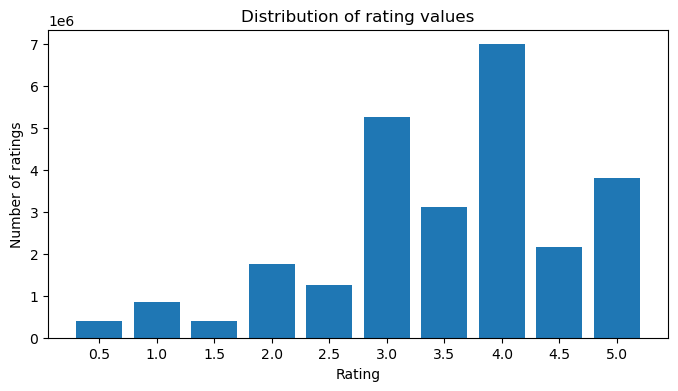

In [6]:
# which rating values exist?
print(f"Unique rating values: {sorted(df['rating'].unique().tolist())}")

# all values within 0.5–5, in half steps?
valid = df["rating"].between(0.5, 5) & ((df["rating"] * 2) % 1 == 0)
print(f"Invalid ratings: {(~valid).sum()}")

# summary statistics
print(df["rating"].describe())

# whole vs half-step ratings
whole = (df["rating"] % 1 == 0).mean()
print(f"Share of whole-number ratings: {whole:.1%}")

# distribution
counts = df["rating"].value_counts().sort_index()
print(counts)

plt.figure(figsize=(8, 4))
plt.bar(counts.index, counts.values, width=0.4)
plt.xticks(counts.index)
plt.xlabel("Rating")
plt.ylabel("Number of ratings")
plt.title("Distribution of rating values")
plt.show()

## 7. Timestamps

First rating: 1995-01-09 11:46:44
Last rating:  2017-08-04 06:57:50
Ratings with timestamp in the future: 0
datetime
1995          4
1996    1733263
1997     763932
1998     329720
1999    1231263
2000    2034030
2001    1239718
2002     910659
2003    1079511
2004    1202081
2005    1850589
2006    1211577
2007    1096103
2008    1211067
2009     993934
2010     983023
2011     835260
2012     793710
2013     634778
2014     586094
2015    1913720
2016    2094961
2017    1295292
Name: count, dtype: int64


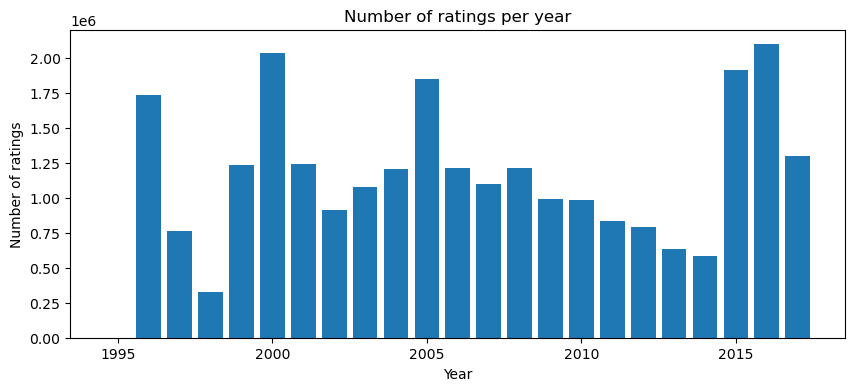

In [7]:
# convert Unix timestamps (seconds) to datetime
df["datetime"] = pd.to_datetime(df["timestamp"], unit="s")

# time span
print(f"First rating: {df['datetime'].min()}")
print(f"Last rating:  {df['datetime'].max()}")

# any suspicious timestamps?
print(f"Ratings with timestamp in the future: {(df['datetime'] > pd.Timestamp.now()).sum()}")

# ratings per year
per_year = df["datetime"].dt.year.value_counts().sort_index()
print(per_year)

plt.figure(figsize=(10, 4))
plt.bar(per_year.index, per_year.values)
plt.xlabel("Year")
plt.ylabel("Number of ratings")
plt.title("Number of ratings per year")
plt.show()

## 8. Ratings per user and per film

Unique users: 270896
Ratings per user:
count    270896.000000
mean         96.067454
std         205.719606
min           1.000000
25%          15.000000
50%          30.000000
75%          93.000000
max       18276.000000
dtype: float64
Users with ≥ 20 ratings: 166444 (61.4%)
Unique movies: 45115

Ratings per movie:
count    45115.000000
mean       576.843378
std       3037.380582
min          1.000000
25%          2.000000
50%          8.000000
75%         69.000000
max      91921.000000
dtype: float64
Movies with only one rating: 7659 (17.0%)


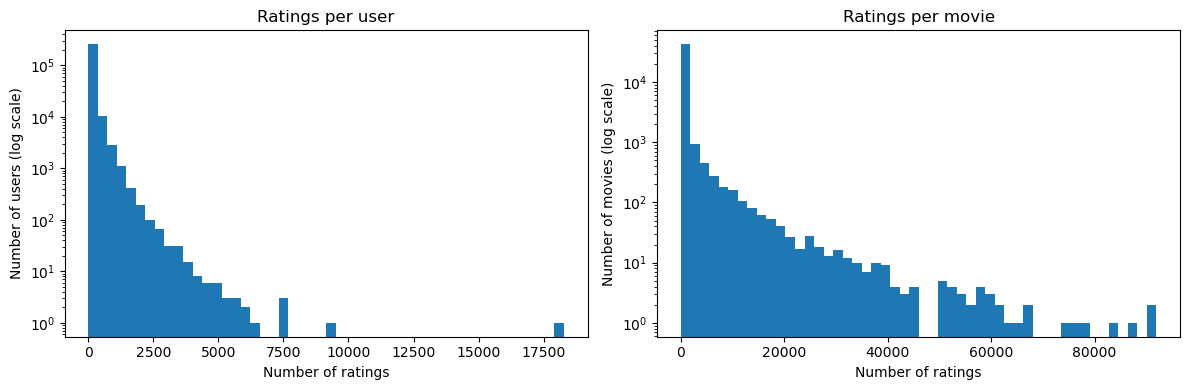

In [8]:
# number of unique users
print(f"Unique users: {df['userId'].nunique()}")

# ratings per user
per_user = df.groupby("userId").size()
print("Ratings per user:")
print(per_user.describe())
print(f"Users with ≥ 20 ratings: {(per_user >= 20).sum()} ({(per_user >= 20).mean():.1%})")

# number of unique movies
print(f"Unique movies: {df['movieId'].nunique()}")

# ratings per movie
per_movie = df.groupby("movieId").size()
print("\nRatings per movie:")
print(per_movie.describe())
print(f"Movies with only one rating: {(per_movie == 1).sum()} ({(per_movie == 1).mean():.1%})")

# histograms with log scale on the y-axis
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(per_user, bins=50)
axes[0].set_yscale("log")
axes[0].set_xlabel("Number of ratings")
axes[0].set_ylabel("Number of users (log scale)")
axes[0].set_title("Ratings per user")

axes[1].hist(per_movie, bins=50)
axes[1].set_yscale("log")
axes[1].set_xlabel("Number of ratings")
axes[1].set_ylabel("Number of movies (log scale)")
axes[1].set_title("Ratings per movie")

plt.tight_layout()
plt.show()

## 9. Rating variance per user

In [9]:
# how much does the ratings vary among users
user_var = df.groupby("userId")["rating"].var(ddof=0)
print(user_var.describe())
print(f"Users with zero variance: {(user_var == 0).sum()}")
print(f"Zero variance among users with ≥ 20 ratings: {((user_var == 0) & (per_user >= 20)).sum()}")

count    270896.000000
mean          0.908549
std           0.585775
min           0.000000
25%           0.513351
50%           0.800000
75%           1.193104
max           5.062500
Name: rating, dtype: float64
Users with zero variance: 7958
Zero variance among users with ≥ 20 ratings: 196


## 10. Findings and decisions

| Finding | Decision |
|---|---|
|The full dataset has 26 024 289 ratings from 270 896 users on 45 115 movies. There are no missing values, no identical rows, and no user has rated the same movie twice.  | No action needed  |
|All ratings are valid: 0.5–5 in half steps. Mean is 3.53 and median is 3.5. 4.0 is the most common value, and 71.8 % of ratings are whole numbers. | No action needed |
|Timestamps are Unix seconds, covering 1995-01-09 to 2017-08-04.  | Convert to datetime before inserting, so it is stored as a date in MongoDB |
|Ratings per user are highly right-skewed: median 30, mean 96, max 18 276.  | No action needed |
|17.0 % of movies have only one rating, and the most-rated movie has 91 921.  | No action needed |
|ratings_small is filtered: every user has at least 20 ratings, compared to a minimum of 1 in the full dataset.  | No action needed |